In [1]:
!pip -q install groq pandas numpy matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.8/143.8 kB 4.7 MB/s eta 0:00:00


In [2]:
import os
import json
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from groq import Groq
from getpass import getpass

In [3]:
GROQ_API_KEY = getpass("Enter your Groq API Key: ")

os.environ["GROQ_API_KEY"] = GROQ_API_KEY

client = Groq(api_key=GROQ_API_KEY)

MODEL = "openai/gpt-oss-20b"

print("Groq client initialized.")
print("Model:", MODEL)

Enter your Groq API Key: ··········
Groq client initialized.
Model: openai/gpt-oss-20b


In [4]:
products = [
    ["P001", "Apple", "iPhone 15", "Smartphone", 69999, 68999, 71999, 67499, 4.6, 82, 18, 145, 8],
    ["P002", "Samsung", "Galaxy S24", "Smartphone", 74999, 72999, 75999, 71499, 4.5, 74, 24, 132, 7],
    ["P003", "OnePlus", "OnePlus 12", "Smartphone", 64999, 61999, 65999, 59999, 4.5, 61, 35, 118, 6],
    ["P004", "Google", "Pixel 9", "Smartphone", 79999, 76999, 78999, 74999, 4.4, 58, 42, 96, 5],

    ["P005", "Apple", "MacBook Air M3", "Laptop", 114999, 109999, 116999, 107999, 4.7, 67, 15, 88, 5],
    ["P006", "HP", "Pavilion 14", "Laptop", 64999, 62999, 65999, 61499, 4.4, 54, 28, 91, 6],
    ["P007", "Lenovo", "IdeaPad Slim 5", "Laptop", 62999, 59999, 63999, 58499, 4.5, 48, 36, 84, 5],
    ["P008", "ASUS", "Vivobook 15", "Laptop", 57999, 55999, 58999, 54499, 4.3, 43, 51, 76, 4],

    ["P009", "Sony", "WH-1000XM5", "Headphones", 34999, 32999, 33999, 31999, 4.7, 76, 19, 125, 7],
    ["P010", "Bose", "QuietComfort", "Headphones", 29999, 28499, 30999, 27499, 4.6, 69, 31, 110, 6],
    ["P011", "JBL", "Tune 770NC", "Headphones", 7999, 7499, 8299, 7199, 4.4, 63, 45, 156, 8],
    ["P012", "Boat", "Rockers 550", "Headphones", 3999, 3699, 4299, 3499, 4.2, 57, 68, 189, 9],

    ["P013", "Apple", "AirPods Pro 2", "Earbuds", 24999, 23999, 24499, 22999, 4.7, 88, 22, 210, 10],
    ["P014", "Samsung", "Galaxy Buds 3", "Earbuds", 15999, 14999, 16499, 14499, 4.5, 72, 39, 167, 8],
    ["P015", "Sony", "WF-1000XM5", "Earbuds", 27999, 26499, 28999, 25499, 4.6, 64, 27, 134, 7],

    ["P016", "Logitech", "MX Master 3S", "Mouse", 9999, 9499, 9799, 9199, 4.7, 71, 34, 143, 7],
    ["P017", "Razer", "DeathAdder V3", "Mouse", 7999, 7499, 8299, 7299, 4.6, 66, 41, 128, 7],
    ["P018", "Logitech", "G102 Lightsync", "Mouse", 2499, 2299, 2399, 2199, 4.5, 81, 75, 245, 10]
]

columns = [
    "product_id",
    "brand",
    "product_name",
    "category",
    "market_price",
    "our_price",
    "competitor_a",
    "competitor_b",
    "rating",
    "demand_index",
    "inventory",
    "sales_velocity",
    "market_trend"
]

df = pd.DataFrame(products, columns=columns)

df.head()

,product_id,brand,product_name,category,market_price,our_price,competitor_a,competitor_b,rating,demand_index,inventory,sales_velocity,market_trend
0,P001,Apple,iPhone 15,Smartphone,69999,68999,71999,67499,4.6,82,18,145,8
1,P002,Samsung,Galaxy S24,Smartphone,74999,72999,75999,71499,4.5,74,24,132,7
2,P003,OnePlus,OnePlus 12,Smartphone,64999,61999,65999,59999,4.5,61,35,118,6
3,P004,Google,Pixel 9,Smartphone,79999,76999,78999,74999,4.4,58,42,96,5
4,P005,Apple,MacBook Air M3,Laptop,114999,109999,116999,107999,4.7,67,15,88,5


In [5]:
print("E-COMMERCE MARKET DATASET")
print("=" * 60)

print("Total Products:", len(df))
print("Categories:", df["category"].nunique())
print("Brands:", df["brand"].nunique())

display(
    df.groupby("category")
      .agg(
          Products=("product_id", "count"),
          Average_Price=("our_price", "mean"),
          Average_Demand=("demand_index", "mean"),
          Average_Rating=("rating", "mean"),
          Average_Inventory=("inventory", "mean")
      )
      .round(2)
      .reset_index()
)

E-COMMERCE MARKET DATASET
Total Products: 18
Categories: 5
Brands: 13


,category,Products,Average_Price,Average_Demand,Average_Rating,Average_Inventory
0,Earbuds,3,21832.33,74.67,4.60,29.33
1,Headphones,4,18174.00,66.25,4.47,40.75
2,Laptop,4,72249.00,53.00,4.47,32.50
3,Mouse,3,6432.33,72.67,4.60,50.00
4,Smartphone,4,70249.00,68.75,4.50,29.75


In [6]:
def competitor_intelligence(product):

    competitor_prices = [
        product["competitor_a"],
        product["competitor_b"]
    ]

    competitor_average = np.mean(competitor_prices)

    price_gap = product["our_price"] - competitor_average

    if price_gap > 0:
        position = "Higher than competitors"
    elif price_gap < 0:
        position = "Lower than competitors"
    else:
        position = "Similar to competitors"

    return {
        "competitor_average": round(competitor_average, 2),
        "price_gap": round(price_gap, 2),
        "position": position,
        "lowest_competitor_price": min(competitor_prices),
        "highest_competitor_price": max(competitor_prices)
    }

In [7]:
def demand_analysis(product):

    demand = product["demand_index"]
    inventory = product["inventory"]
    velocity = product["sales_velocity"]

    if demand >= 75:
        demand_level = "High"
    elif demand >= 50:
        demand_level = "Medium"
    else:
        demand_level = "Low"

    if inventory <= 25:
        inventory_level = "Low"
    elif inventory <= 50:
        inventory_level = "Medium"
    else:
        inventory_level = "High"

    if velocity >= 180:
        velocity_level = "Very High"
    elif velocity >= 120:
        velocity_level = "High"
    elif velocity >= 80:
        velocity_level = "Medium"
    else:
        velocity_level = "Low"

    return {
        "demand_level": demand_level,
        "inventory_level": inventory_level,
        "sales_velocity_level": velocity_level
    }

In [8]:
def dynamic_pricing_agent(product):

    competitor_info = competitor_intelligence(product)
    demand_info = demand_analysis(product)

    current_price = product["our_price"]
    competitor_average = competitor_info["competitor_average"]

    adjustment = 0

    if demand_info["demand_level"] == "High":
        adjustment += 0.04
    elif demand_info["demand_level"] == "Low":
        adjustment -= 0.04

    if demand_info["inventory_level"] == "Low":
        adjustment += 0.03
    elif demand_info["inventory_level"] == "High":
        adjustment -= 0.03

    if current_price > competitor_average:
        adjustment -= 0.02

    if current_price < competitor_average:
        adjustment += 0.01

    recommended_price = current_price * (1 + adjustment)

    lower_bound = competitor_info["lowest_competitor_price"] * 0.98
    upper_bound = competitor_info["highest_competitor_price"] * 1.05

    recommended_price = np.clip(
        recommended_price,
        lower_bound,
        upper_bound
    )

    recommended_price = round(recommended_price / 100) * 100

    if recommended_price > current_price:
        action = "Increase Price"
    elif recommended_price < current_price:
        action = "Decrease Price"
    else:
        action = "Keep Price"

    return {
        "recommended_price": int(recommended_price),
        "action": action,
        "adjustment_percent": round(
            ((recommended_price - current_price) / current_price) * 100,
            2
        ),
        "competitor_analysis": competitor_info,
        "demand_analysis": demand_info
    }

In [9]:
product_id = "P001"

selected_product = df[
    df["product_id"] == product_id
].iloc[0]

print("SELECTED PRODUCT")
print("=" * 60)

print("Product:", selected_product["product_name"])
print("Brand:", selected_product["brand"])
print("Category:", selected_product["category"])
print("Current Price: ₹", selected_product["our_price"])
print("Rating:", selected_product["rating"])

SELECTED PRODUCT
Product: iPhone 15
Brand: Apple
Category: Smartphone
Current Price: ₹ 68999
Rating: 4.6


In [10]:
product = selected_product.to_dict()

competitor_result = competitor_intelligence(product)

print("COMPETITOR INTELLIGENCE")
print("=" * 60)

print("Our Price: ₹", product["our_price"])
print(
    "Competitor A: ₹",
    product["competitor_a"]
)
print(
    "Competitor B: ₹",
    product["competitor_b"]
)

print(
    "Average Competitor Price: ₹",
    competitor_result["competitor_average"]
)

print(
    "Price Gap: ₹",
    competitor_result["price_gap"]
)

print(
    "Market Position:",
    competitor_result["position"]
)

COMPETITOR INTELLIGENCE
Our Price: ₹ 68999
Competitor A: ₹ 71999
Competitor B: ₹ 67499
Average Competitor Price: ₹ 69749.0
Price Gap: ₹ -750.0
Market Position: Lower than competitors


In [11]:
demand_result = demand_analysis(product)

print("DEMAND & INVENTORY ANALYSIS")
print("=" * 60)

print("Demand Index:", product["demand_index"])
print("Demand Level:", demand_result["demand_level"])

print("Inventory:", product["inventory"])
print("Inventory Level:", demand_result["inventory_level"])

print("Sales Velocity:", product["sales_velocity"])
print(
    "Sales Velocity Level:",
    demand_result["sales_velocity_level"]
)

DEMAND & INVENTORY ANALYSIS
Demand Index: 82
Demand Level: High
Inventory: 18
Inventory Level: Low
Sales Velocity: 145
Sales Velocity Level: High


In [12]:
pricing_result = dynamic_pricing_agent(product)

print("DYNAMIC PRICING RESULT")
print("=" * 60)

print("Current Price: ₹", product["our_price"])

print(
    "Recommended Price: ₹",
    pricing_result["recommended_price"]
)

print(
    "Action:",
    pricing_result["action"]
)

print(
    "Price Adjustment:",
    pricing_result["adjustment_percent"],
    "%"
)

DYNAMIC PRICING RESULT
Current Price: ₹ 68999
Recommended Price: ₹ 74500
Action: Increase Price
Price Adjustment: 7.97 %


In [13]:
def dynamic_pricing_workflow(product_id):

    print("\n" + "=" * 80)
    print("DYNAMIC PRICING & COMPETITOR INTELLIGENCE AGENT")
    print("=" * 80)

    product = df[
        df["product_id"] == product_id
    ].iloc[0].to_dict()

    print("\n[1] PRODUCT IDENTIFICATION")

    print(
        "Product:",
        product["product_name"]
    )

    print(
        "Current Price: ₹",
        product["our_price"]
    )

    print("\n[2] COMPETITOR INTELLIGENCE")

    competitor_result = competitor_intelligence(product)

    print(
        "Average Competitor Price: ₹",
        competitor_result["competitor_average"]
    )

    print(
        "Market Position:",
        competitor_result["position"]
    )

    print("\n[3] DEMAND & INVENTORY ANALYSIS")

    demand_result = demand_analysis(product)

    print(
        "Demand Level:",
        demand_result["demand_level"]
    )

    print(
        "Inventory Level:",
        demand_result["inventory_level"]
    )

    print(
        "Sales Velocity:",
        demand_result["sales_velocity_level"]
    )

    print("\n[4] DYNAMIC PRICE CALCULATION")

    pricing_result = dynamic_pricing_agent(product)

    print(
        "Recommended Price: ₹",
        pricing_result["recommended_price"]
    )

    print(
        "Action:",
        pricing_result["action"]
    )

    print(
        "Adjustment:",
        pricing_result["adjustment_percent"],
        "%"
    )

    return {
        "product": product,
        "competitor": competitor_result,
        "demand": demand_result,
        "pricing": pricing_result
    }

In [14]:
experiment = dynamic_pricing_workflow("P001")


DYNAMIC PRICING & COMPETITOR INTELLIGENCE AGENT

[1] PRODUCT IDENTIFICATION
Product: iPhone 15
Current Price: ₹ 68999

[2] COMPETITOR INTELLIGENCE
Average Competitor Price: ₹ 69749.0
Market Position: Lower than competitors

[3] DEMAND & INVENTORY ANALYSIS
Demand Level: High
Inventory Level: Low
Sales Velocity: High

[4] DYNAMIC PRICE CALCULATION
Recommended Price: ₹ 74500
Action: Increase Price
Adjustment: 7.97 %


In [15]:
def explain_pricing_decision(experiment):

    product = experiment["product"]
    competitor = experiment["competitor"]
    demand = experiment["demand"]
    pricing = experiment["pricing"]

    prompt = f"""
You are the Explanation Agent of an E-Commerce
Dynamic Pricing and Competitor Intelligence System.

Product:
{product["product_name"]}

Brand:
{product["brand"]}

Category:
{product["category"]}

Current Price:
₹{product["our_price"]}

Competitor Average Price:
₹{competitor["competitor_average"]}

Lowest Competitor Price:
₹{competitor["lowest_competitor_price"]}

Highest Competitor Price:
₹{competitor["highest_competitor_price"]}

Market Position:
{competitor["position"]}

Demand Level:
{demand["demand_level"]}

Inventory Level:
{demand["inventory_level"]}

Sales Velocity:
{demand["sales_velocity_level"]}

Recommended Price:
₹{pricing["recommended_price"]}

Recommended Action:
{pricing["action"]}

Price Adjustment:
{pricing["adjustment_percent"]}%

Explain:

1. How competitor prices affected the decision
2. How demand and inventory affected the decision
3. Why the recommended action was generated
4. What market trade-off exists

Do not invent product specifications.
Keep the explanation concise and factual.
"""

    response = client.chat.completions.create(
        model=MODEL,
        messages=[
            {
                "role": "system",
                "content": "You explain structured e-commerce pricing decisions."
            },
            {
                "role": "user",
                "content": prompt
            }
        ],
        reasoning_effort="medium"
    )

    return response.choices[0].message.content

In [16]:
explanation = explain_pricing_decision(experiment)

print("\nFINAL PRICING DECISION EXPLANATION")
print("=" * 70)

print(explanation)


FINAL PRICING DECISION EXPLANATION
**1. Competitor pricing impact**  
- The average competitor price (₹69,749) and the highest competitor price (₹71,999) are above the current iPhone 15 price of ₹68,999.  
- Because our price is already lower than competitors, a price increase is possible without crossing the lowest competitor price (₹67,499).  
- The 7.97 % increase brings the price to ₹74,500, still below the highest competitor level, preserving a competitive stance while aligning closer to the market average.

**2. Demand and inventory impact**  
- Demand is high and sales velocity is strong, indicating robust consumer interest.  
- Inventory is low; raising the price helps protect the remaining stock by extracting higher revenue per unit before the supply runs out.  
- The higher price can also moderate the demand curve slightly, slowing velocity enough to extend the inventory lifespan without a drastic drop in sales.

**3. Reason for the recommended action**  
- The algorithm ide

In [17]:
print("=" * 80)
print("AGENT WORKFLOW STATE")
print("=" * 80)

print("\n1. PRODUCT")
print(experiment["product"]["product_name"])

print("\n2. CURRENT PRICE")
print("₹", experiment["product"]["our_price"])

print("\n3. COMPETITOR ANALYSIS")
print(
    "Competitor Average: ₹",
    experiment["competitor"]["competitor_average"]
)

print(
    "Market Position:",
    experiment["competitor"]["position"]
)

print("\n4. DEMAND ANALYSIS")
print(
    "Demand:",
    experiment["demand"]["demand_level"]
)

print(
    "Inventory:",
    experiment["demand"]["inventory_level"]
)

print(
    "Sales Velocity:",
    experiment["demand"]["sales_velocity_level"]
)

print("\n5. PRICING DECISION")

print(
    "Recommended Price: ₹",
    experiment["pricing"]["recommended_price"]
)

print(
    "Action:",
    experiment["pricing"]["action"]
)

print(
    "Adjustment:",
    experiment["pricing"]["adjustment_percent"],
    "%"
)

print("\n6. FINAL EXPLANATION")
print(explanation)

AGENT WORKFLOW STATE

1. PRODUCT
iPhone 15

2. CURRENT PRICE
₹ 68999

3. COMPETITOR ANALYSIS
Competitor Average: ₹ 69749.0
Market Position: Lower than competitors

4. DEMAND ANALYSIS
Demand: High
Inventory: Low
Sales Velocity: High

5. PRICING DECISION
Recommended Price: ₹ 74500
Action: Increase Price
Adjustment: 7.97 %

6. FINAL EXPLANATION
**1. Competitor pricing impact**  
- The average competitor price (₹69,749) and the highest competitor price (₹71,999) are above the current iPhone 15 price of ₹68,999.  
- Because our price is already lower than competitors, a price increase is possible without crossing the lowest competitor price (₹67,499).  
- The 7.97 % increase brings the price to ₹74,500, still below the highest competitor level, preserving a competitive stance while aligning closer to the market average.

**2. Demand and inventory impact**  
- Demand is high and sales velocity is strong, indicating robust consumer interest.  
- Inventory is low; raising the price helps prote

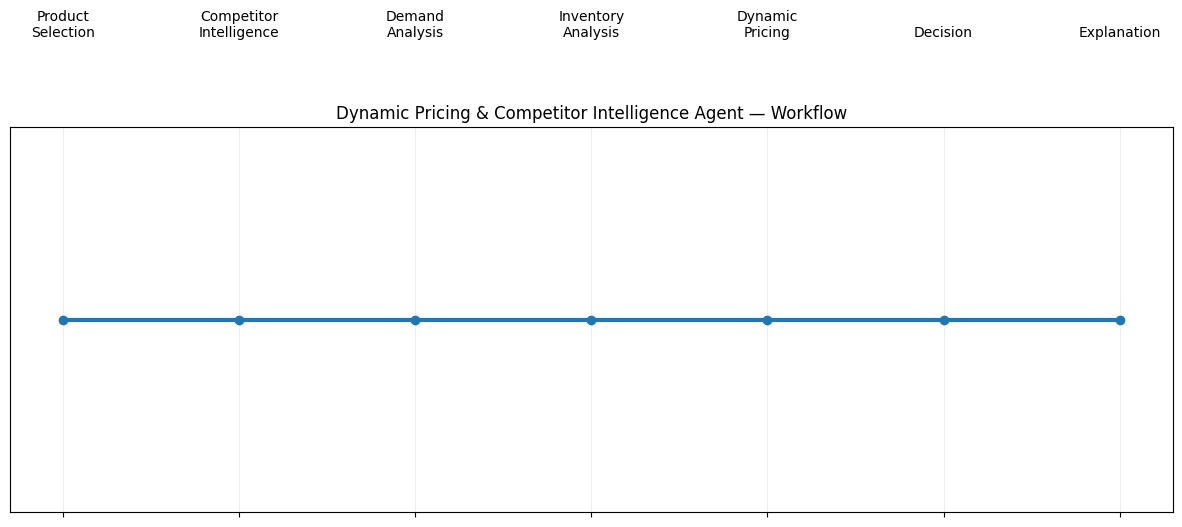

In [18]:
steps = [
    "Product\nSelection",
    "Competitor\nIntelligence",
    "Demand\nAnalysis",
    "Inventory\nAnalysis",
    "Dynamic\nPricing",
    "Decision",
    "Explanation"
]

x = np.arange(len(steps))

plt.figure(figsize=(15, 5))

plt.plot(
    x,
    np.zeros(len(x)),
    marker="o",
    linewidth=3
)

for i, step in enumerate(steps):

    plt.text(
        i,
        0.08,
        step,
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.yticks([])
plt.xticks(x, [])

plt.title(
    "Dynamic Pricing & Competitor Intelligence Agent — Workflow"
)

plt.grid(
    axis="x",
    alpha=0.2
)

plt.show()

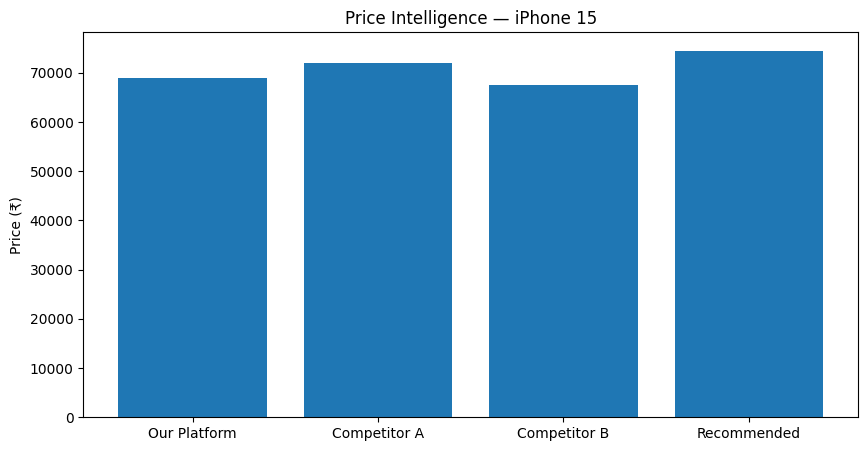

In [19]:
product = experiment["product"]

competitor_names = [
    "Our Platform",
    "Competitor A",
    "Competitor B",
    "Recommended"
]

prices = [
    product["our_price"],
    product["competitor_a"],
    product["competitor_b"],
    experiment["pricing"]["recommended_price"]
]

plt.figure(figsize=(10, 5))

plt.bar(
    competitor_names,
    prices
)

plt.ylabel("Price (₹)")

plt.title(
    f"Price Intelligence — {product['product_name']}"
)

plt.show()

In [20]:
experiment2 = dynamic_pricing_workflow("P009")

explanation2 = explain_pricing_decision(
    experiment2
)

print("\nFINAL EXPLANATION")
print("=" * 70)

print(explanation2)


DYNAMIC PRICING & COMPETITOR INTELLIGENCE AGENT

[1] PRODUCT IDENTIFICATION
Product: WH-1000XM5
Current Price: ₹ 32999

[2] COMPETITOR INTELLIGENCE
Average Competitor Price: ₹ 32999.0
Market Position: Similar to competitors

[3] DEMAND & INVENTORY ANALYSIS
Demand Level: High
Inventory Level: Low
Sales Velocity: High

[4] DYNAMIC PRICE CALCULATION
Recommended Price: ₹ 35300
Action: Increase Price
Adjustment: 6.97 %

FINAL EXPLANATION
**Explanation**

1. **Competitor prices**  
   • The average competitor price is ₹32,999, identical to the current price.  
   • The lowest competitor price is ₹31,999 and the highest is ₹33,999.  
   • Since our price matches the market average but is higher than the lowest competitor, a modest increase keeps us competitive while still above the low‑end offers.  

2. **Demand & inventory**  
   • Demand is high and sales velocity is high, indicating strong customer interest.  
   • Inventory is low, so there is pressure to allocate remaining stock efficie

In [21]:
test_products = [
    "P001",
    "P005",
    "P009",
    "P013",
    "P018"
]

pricing_results = []

for product_id in test_products:

    product = df[
        df["product_id"] == product_id
    ].iloc[0]

    result = dynamic_pricing_agent(
        product.to_dict()
    )

    pricing_results.append({
        "Product": product["product_name"],
        "Current Price": product["our_price"],
        "Competitor Average": result[
            "competitor_analysis"
        ]["competitor_average"],
        "Demand": result[
            "demand_analysis"
        ]["demand_level"],
        "Inventory": result[
            "demand_analysis"
        ]["inventory_level"],
        "Recommended Price": result[
            "recommended_price"
        ],
        "Action": result["action"],
        "Adjustment %": result[
            "adjustment_percent"
        ]
    })

pricing_df = pd.DataFrame(
    pricing_results
)

display(pricing_df)

,Product,Current Price,Competitor Average,Demand,Inventory,Recommended Price,Action,Adjustment %
0,iPhone 15,68999,69749.0,High,Low,74500,Increase Price,7.97
1,MacBook Air M3,109999,112499.0,Medium,Low,114400,Increase Price,4.00
2,WH-1000XM5,32999,32999.0,High,Low,35300,Increase Price,6.97
3,AirPods Pro 2,23999,23749.0,High,Low,25200,Increase Price,5.00
4,G102 Lightsync,2299,2299.0,High,High,2300,Increase Price,0.04


In [24]:
user_query = input("Enter your pricing query: ")

product_id = "P001"

print("\nUSER QUERY")
print("=" * 60)
print(user_query)

experiment = dynamic_pricing_workflow(product_id)

explanation = explain_pricing_decision(experiment)

print("\nFINAL AGENT RESPONSE")
print("=" * 60)
print(explanation)

Enter your pricing query: compare iphone prices of our store and out competitor

USER QUERY
compare iphone prices of our store and out competitor

DYNAMIC PRICING & COMPETITOR INTELLIGENCE AGENT

[1] PRODUCT IDENTIFICATION
Product: iPhone 15
Current Price: ₹ 68999

[2] COMPETITOR INTELLIGENCE
Average Competitor Price: ₹ 69749.0
Market Position: Lower than competitors

[3] DEMAND & INVENTORY ANALYSIS
Demand Level: High
Inventory Level: Low
Sales Velocity: High

[4] DYNAMIC PRICE CALCULATION
Recommended Price: ₹ 74500
Action: Increase Price
Adjustment: 7.97 %

FINAL AGENT RESPONSE
**Pricing Decision Overview – iPhone 15 (Apple, Smartphone)**  

1. **Competitor price impact**  
   - The product is priced ₹68999, below the competitor average of ₹69749.  
   - Competitors range from ₹67499 (lowest) to ₹71999 (highest).  
   - Being lower than the average and near the lower bound gives a price‑lead advantage, but also limits upside potential.  
   - The system therefore seeks to close the ga

In [ ]:
user_query = input("Enter your pricing query: ")

product_id = "P001"

experiment = dynamic_pricing_workflow(product_id)

prompt = f"""
You are an E-Commerce Dynamic Pricing Agent.

User Query:
{user_query}

Product:
{experiment["product"]["product_name"]}

Current Price:
₹{experiment["product"]["our_price"]}

Competitor Average:
₹{experiment["competitor"]["competitor_average"]}

Market Position:
{experiment["competitor"]["position"]}

Demand:
{experiment["demand"]["demand_level"]}

Inventory:
{experiment["demand"]["inventory_level"]}

Sales Velocity:
{experiment["demand"]["sales_velocity_level"]}

Recommended Price:
₹{experiment["pricing"]["recommended_price"]}

Action:
{experiment["pricing"]["action"]}

Answer the user's query using the provided data.
Explain the pricing decision clearly and do not invent information.
"""

response = client.chat.completions.create(
    model=MODEL,
    messages=[
        {
            "role": "system",
            "content": "You are an e-commerce dynamic pricing agent."
        },
        {
            "role": "user",
            "content": prompt
        }
    ],
    reasoning_effort="medium"
)

print("\nAGENT RESPONSE")
print("=" * 60)
print(response.choices[0].message.content)